# Import

In [1]:
%reset -f
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import meshio
import sys
sys.path.append('../')

from sources.parameters import *
from sources.data import *
from sources.model import *
from sources.solver import *

2022-09-07 12:44:03.217645: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:936] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2022-09-07 12:44:03.234766: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudnn.so.8'; dlerror: libcudnn.so.8: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: :/run/user/1000/doc:/run/user/1000/doc
2022-09-07 12:44:03.234778: W tensorflow/core/common_runtime/gpu/gpu_device.cc:1850] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...
2022-09-07 12:44:03.235156: I tensorflow/core/platform/cpu_feature_guard.cc:151] This TensorFlow binary is 

# load weights

In [3]:
# Set boundary
tmin = 0.
tmax = 1.5
xmin = 0.
xmax = 1.
ymin = 0. 
ymax = 1.

# Lower bounds
lb = tf.constant([tmin, xmin, ymin], dtype=DTYPE)
# Upper bounds
ub = tf.constant([tmax, xmax, ymax], dtype=DTYPE)

In [4]:
model = PhysicsInformedNN(lb, ub, num_hidden_layers=8, num_neurons_per_layer=150, activation='tanh')
model.build(input_shape=(None,3))
model.load_weights(WEIGHT_PATH+'best_weight-hubert2.h5')

# plot solution 

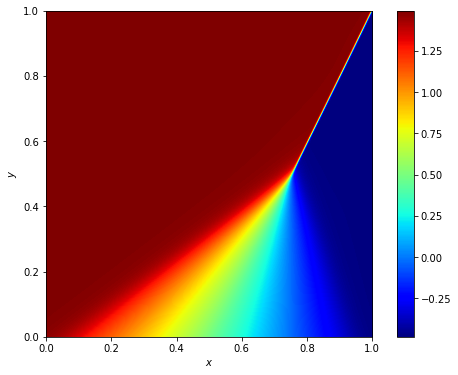

In [5]:
N = 800

# compute solution using PINN
xspace = np.linspace(0,1,N)
yspace = np.linspace(0,1,N)
tfinal = 1.5 * np.ones(N*N)

X, Y = np.meshgrid(xspace, yspace)
Xgrid = np.vstack([tfinal.flatten(), X.flatten(), Y.flatten()]).T
upred = model(tf.cast(Xgrid,DTYPE))

# reshape for plotting
U = upred.numpy().reshape(N,N)

# plot solution
fig = plt.figure(figsize=(9,6))
ax = fig.add_subplot(111)
ax.set_xlabel('$x$')
ax.set_ylabel('$y$')  
img = ax.imshow(U, cmap='jet', origin='lower', extent=[0.,1.,0.,1.])
fig.colorbar(img);

# compare with data

0.8 rot1600.vtk
1.0 rot2000.vtk
1.2 rot2400.vtk
1.5 rot3000.vtk


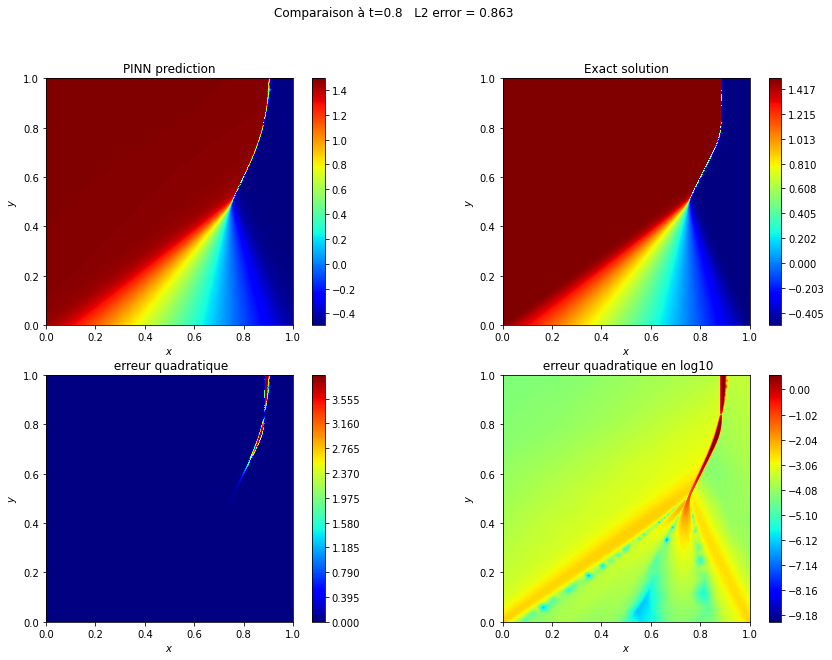

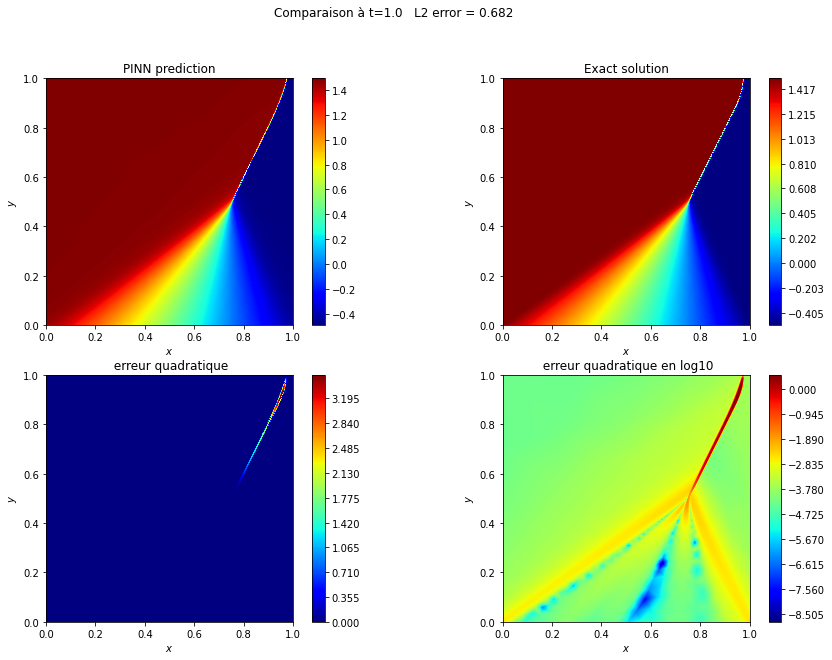

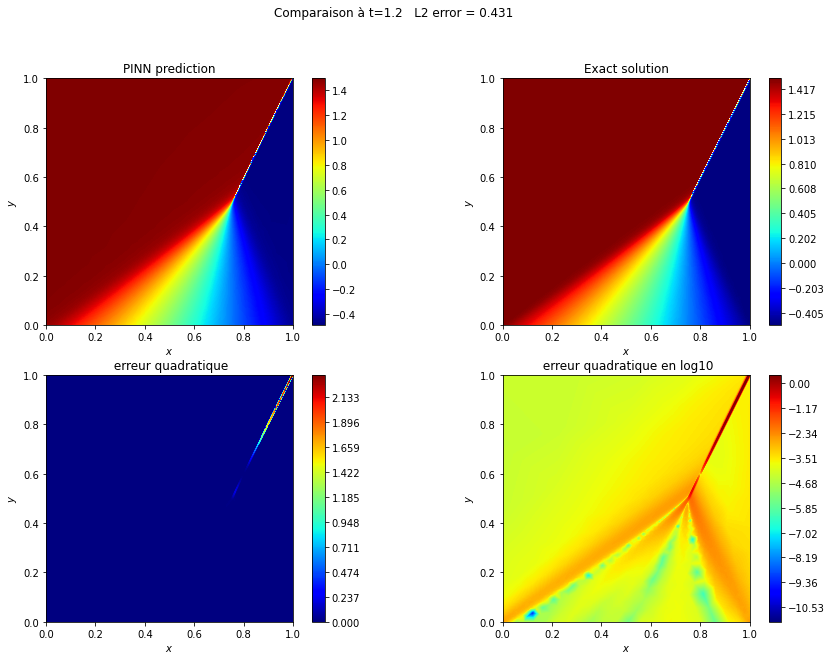

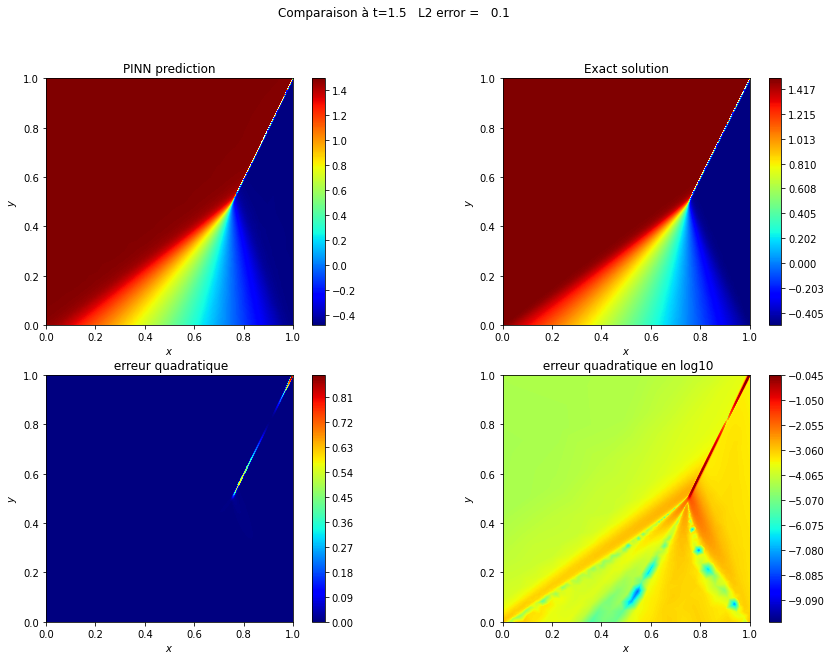

In [6]:
solutions = {
             0.8: 'rot1600.vtk',
             1.0: 'rot2000.vtk',
             1.2: 'rot2400.vtk',
             1.5: 'rot3000.vtk'
            }

for time, filename in solutions.items():
    print(time, filename)

for time, filename in solutions.items():

    # lecture des données du maillage
    reader = meshio.read(DATA_PATH+filename)

    x = reader.points
    triangles =  reader.cells_dict['triangle']
    u_exact = reader.point_data['solution']

    # prediction du PINN
    N = len(x)
    tfinal = time * np.ones(N)
    Xtest = np.vstack([tfinal.flatten(), x[:,0].flatten(), x[:,1].flatten()]).T
    upred = model(tf.cast(Xtest,DTYPE))

    # calcul de l'erreur
    diff = tf.square(upred[:,0] - u_exact)
    error = tf.reduce_mean(diff)

    # affichage
    fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(15,10))
    axs = axs.flatten()

    # prediction du PINN
    axs[0].set_xlabel('$x$')
    axs[0].set_ylabel('$y$')
    axs[0].set_aspect('equal')
    img0 = axs[0].tricontourf(x[:,0], x[:,1], triangles, upred.numpy().flatten(), 800, cmap='jet', extent=[0.,1.,0.,1.]);
    cbar0 = plt.colorbar(img0, ax=axs[0])
    axs[0].set_title('PINN prediction')

    # solution exacte
    axs[1].set_xlabel('$x$')
    axs[1].set_ylabel('$y$')
    axs[1].set_aspect('equal')
    #axs[1].triplot(x[:,0], x[:,1], triangles, lw=0.5)
    img1 = axs[1].tricontourf(x[:,0], x[:,1], triangles, u_exact, 800, cmap='jet', vmin=-.5, vmax=1.5);
    cbar1 = plt.colorbar(img1, ax=axs[1])
    axs[1].set_title('Exact solution')

    # erreur entre les deux
    axs[2].set_xlabel('$x$')
    axs[2].set_ylabel('$y$')
    axs[2].set_aspect('equal')
    img2 = axs[2].tricontourf(x[:,0], x[:,1], triangles, diff, 800, cmap='jet', extent=[0.,1.,0.,1.]);
    cbar2 = plt.colorbar(img2, ax=axs[2])
    axs[2].set_title(' erreur quadratique')

    # erreur en log10
    axs[3].set_xlabel('$x$')
    axs[3].set_ylabel('$y$')
    axs[3].set_aspect('equal')
    img3 = axs[3].tricontourf(x[:,0], x[:,1], triangles, tf.math.log(diff)/np.log(10), 800, cmap='jet', extent=[0.,1.,0.,1.]);
    cbar3 = plt.colorbar(img3, ax=axs[3])
    axs[3].set_title(' erreur quadratique en log10')

    #fig.tight_layout()
    plt.suptitle('Comparaison à t={}   L2 error = {:5.3}'.format(time, error))
    plt.savefig(FIG_PATH+'burgers2d'+str(int(time*10)), bbox_inches='tight', dpi=fig.dpi, facecolor='w', edgecolor='w', transparent=False)
    plt.show()

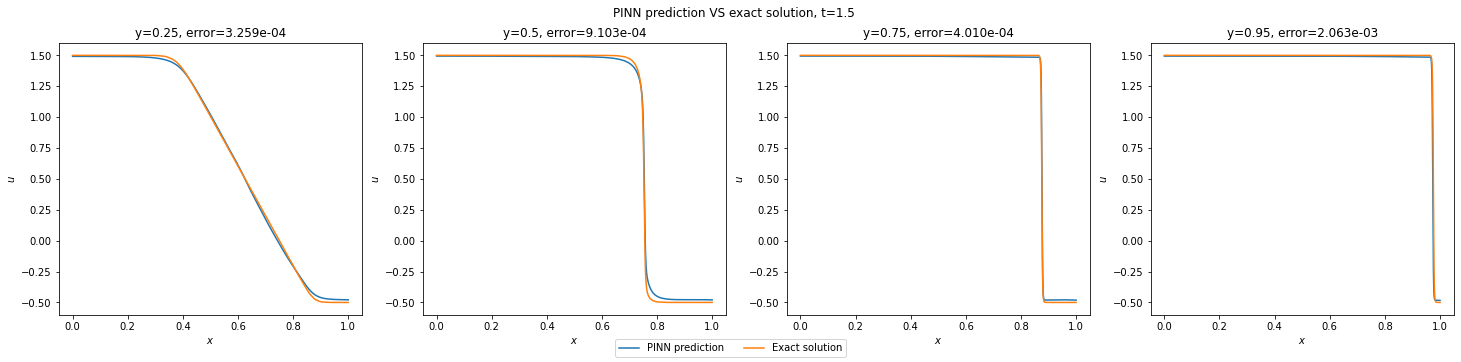

In [7]:
solutions = {
             0.25: '025.csv',
             0.50: '050.csv',
             0.75: '075.csv',
             0.95: '095.csv'
            }

fig, ax = plt.subplots(1, 4, figsize=(25, 5))
ax = ax.flatten()

for i, (y, filename) in enumerate(solutions.items()):

    # load exact solution 
    csv = np.genfromtxt (DATA_PATH+filename, delimiter=",", skip_header=1)
    u_exact = csv[:,0]
    xspace = csv[:,3]

    # PINN prediction
    N = len(xspace)
    yspace = y * np.ones(N)
    tfinal = 1.5 * np.ones(N)
    Xgrid = np.vstack([tfinal.flatten(), xspace.flatten(), yspace.flatten()]).T
    upred = model(tf.cast(Xgrid,DTYPE))
    upred = upred.numpy().flatten()

    # error
    error = np.mean((u_exact-upred)**2)

    # plot 
    ax[i].set_xlabel('$x$')
    ax[i].set_ylabel('$u$')  
    ax[i].plot(xspace, upred, label='PINN prediction')
    ax[i].plot(xspace, u_exact, label='Exact solution')
    ax[i].set_title('y={}, error={:5.3e}'.format(y,error))

handles, labels = ax[-1].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2);
plt.suptitle('PINN prediction VS exact solution, t=1.5');
plt.savefig(FIG_PATH+'burgers2d_slices' , bbox_inches='tight', dpi=fig.dpi, facecolor='w', edgecolor='w', transparent=False)